# URL Classification with XGBoost And Lexical Feature with Hash Encoding and Random Oversampling

Notebook ini bertujuan untuk mengklasifikasikan URL sebagai benign atau malicious menggunakan model XGBoost. Kami akan melakukan beberapa langkah berikut:

1. **Konfigurasi**: Menetapkan jalur data dan model.
2. **Fungsi Feature Engineering**: Mendefinisikan fungsi-fungsi untuk ekstraksi fitur dari URL.
3. **Memuat Dataset**: Membaca dataset dari file CSV.
4. **Eksplorasi Dataset**: Melihat sekilas data dan distribusi kelas.
5. **Visualisasi Word Clouds**: Menghasilkan word cloud untuk setiap kelas URL.
6. **Feature Engineering**: Menerapkan fungsi-fungsi feature engineering pada data.
7. **Hash Encoding untuk Kolom 'tld'**: Mengubah data kategorikal `tld` menjadi numerik menggunakan hash encoding.
8. **Seleksi Fitur**: Memilih fitur-fitur yang relevan untuk pelatihan model.
9. **Label Encoding**: Mengubah label target menjadi format numerik.
10. **Menangani Nilai Hilang**: Mengisi nilai yang hilang pada fitur kategorikal.
11. **Encoding Fitur Kategorikal dengan TargetEncoder**: Menggunakan TargetEncoder untuk mengubah fitur kategorikal menjadi numerik.
12. **Cross-Validation dengan XGBoost**: Melakukan cross-validation untuk mengevaluasi model.
13. **Ringkasan Metrik Cross-Validation**: Menghitung rata-rata akurasi dan mengagregasi feature importances.
14. **Pelatihan Model Final**: Melatih model XGBoost akhir pada seluruh dataset.
15. **Prediksi pada URL Uji**: Menggunakan model akhir untuk memprediksi jenis URL pada data uji.


## 1. Konfigurasi

Menetapkan jalur data dan lokasi penyimpanan model serta encoder.

In [18]:
# 1. Konfigurasi

# Path to your dataset CSV file
DATA_PATH = './malicious_phish.csv'

# Path to save models and encoders
MODEL_PATH = './models/final_xgb_model.pkl'
ENCODER_PATH = './models/target_encoder.pkl'
LABEL_ENCODER_PATH = './models/label_encoder.pkl'

## 2. Import Libraries

Mengimpor semua library yang diperlukan untuk proses klasifikasi URL.

In [19]:
# 2. Import Libraries

import hashlib
import joblib
from IPython.display import display
from category_encoders import TargetEncoder
import ipaddress
from imblearn.over_sampling import RandomOverSampler
from xgboost import XGBClassifier
from sklearn import metrics
from wordcloud import WordCloud
import seaborn as sns
import matplotlib.pyplot as plt
import tldextract
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from joblib import dump, load
import pandas as pd
from urllib.parse import urlparse, parse_qs, urlsplit
import string
import re
import os
import numpy as np
import itertools
import csv

sns.set(style="whitegrid")

## 3. Fungsi Feature Engineering

Mendefinisikan berbagai fungsi untuk mengekstraksi fitur dari URL.

In [20]:
# 3. Feature Engineering Functions

# Daftar TLD terpercaya
TRUSTED_TLDS = {
    # TLD Generik Umum
    'com', 'org', 'net', 'edu', 'gov', 'mil', 'int', 'info', 'co', 'biz', 'me', 'pro',
    'ai', 'dev', 'shop', 'tech', 'store', 'io', 'online', 'site', 'website', 'app', 'club',
    'news', 'health', 'travel', 'blog', 'design', 'media', 'agency',
    
    # TLD Indonesia yang terpercaya
    'ac.id', 'sch.id', 'go.id', 'or.id', 'web.id', 'co.id', 'my.id', 'ponpes.id',
    'biz.id', 'net.id', 'com.id', 'desa.id',
    
    # TLD Internasional lainnya yang terpercaya
    # United Kingdom
    'co.uk', 'gov.uk', 'ac.uk', 'org.uk', 'me.uk', 'ltd.uk', 'plc.uk', 'net.uk',
    
    # Australia
    'edu.au', 'gov.au', 'com.au', 'org.au', 'net.au', 'id.au', 'asn.au',
    
    # Kanada
    'ca', 'gc.ca', 'co.ca', 'org.ca', 'net.ca',
    
    # Jepang
    'co.jp', 'ac.jp', 'ad.jp', 'ed.jp', 'go.jp', 'or.jp', 'ne.jp',
    
    # Jerman
    'de', 'ac.de', 'gov.de', 'edu.de', 'org.de', 'net.de',
    
    # Prancis
    'fr', 'ac.fr', 'gov.fr', 'asso.fr', 'org.fr', 'com.fr',
    
    # Amerika Serikat
    'us', 'edu.us', 'gov.us', 'mil.us', 'net.us', 'org.us',
    
    # Belanda
    'nl', 'bv.nl', 'voornaam.nl', 'achternaam.nl',
    
    # Singapura
    'sg', 'com.sg', 'net.sg', 'org.sg', 'gov.sg', 'edu.sg',
    
    # Korea Selatan
    'kr', 'co.kr', 'ne.kr', 'or.kr', 're.kr', 'pe.kr',
    
    # Cina
    'cn', 'com.cn', 'net.cn', 'org.cn', 'gov.cn', 'edu.cn',
    
    # Brasil
    'br', 'com.br', 'net.br', 'org.br', 'gov.br', 'edu.br',
    
    # Rusia
    'ru', 'com.ru', 'net.ru', 'org.ru', 'gov.ru', 'edu.ru',
    
    # India
    'in', 'co.in', 'net.in', 'org.in', 'firm.in', 'gen.in', 'ind.in',
    
    # Afrika Selatan
    'za', 'co.za', 'org.za', 'net.za', 'gov.za', 'mil.za', 'ac.za',
    
    # Uni Emirat Arab
    'ae', 'co.ae', 'net.ae', 'org.ae', 'gov.ae', 'sch.ae',
    
    # Seluruh Dunia
    'eu', 'asia', 'mobi', 'museum', 'travel', 'jobs', 'name', 'post', 'tel', 'tv', 'cc',
    'me', 'us', 'ca', 'uk', 'de', 'jp', 'fr', 'au', 'cn', 'br', 'ru', 'in', 'za', 'sg',
    'kr', 'it', 'es', 'nl', 'se', 'no', 'fi', 'dk', 'be', 'ch', 'at', 'pl', 'cz', 'hu',
    'sk', 'si', 'ro', 'bg', 'gr', 'tr', 'il', 'my', 'th', 'vn', 'id', 'ph', 'tw', 'hk'
}

def secure_http(url):
    """Count the number of 'https' occurrences in the URL."""
    try:
        return url.lower().count('https')
    except:
        return 0

def url_length(url):
    """Calculate the length of the URL excluding the scheme."""
    try:
        return len(url.replace('http://', '', 1).replace('https://', '', 1))
    except:
        return 0

def find_subdomain(url):
    """Extract the subdomain from the URL."""
    try:
        ext = tldextract.extract(url)
        return ext.subdomain if ext.subdomain else 'missing'
    except:
        return 'missing'

def get_tld_func(url):
    """Extract the top-level domain (TLD) from the URL."""
    try:
        ext = tldextract.extract(url)
        return ext.suffix if ext.suffix else 'missing'
    except:
        return 'missing'

def domain_token_count(url):
    """Count the number of tokens in the domain."""
    try:
        parsed_url = urlparse(url if urlparse(url).scheme else 'http://' + url)
        domain = parsed_url.netloc
        # Remove IPv6 brackets if present
        if domain.startswith('[') and domain.endswith(']'):
            domain = domain[1:-1]
        return len(domain.split('.')) if domain else 0
    except ValueError:
        # Handle invalid IPv6 URLs or other parsing errors
        return 0
    except:
        return 0

def hostname_length(url):
    """Calculate the length of the hostname."""
    try:
        parsed_url = urlparse(url if urlparse(url).scheme else 'http://' + url)
        hostname = parsed_url.hostname
        return len(hostname) if hostname else 0
    except:
        return 0

def extract_root_domain(url):
    """Extract the root domain from the URL."""
    try:
        extracted = tldextract.extract(url)
        return extracted.domain if extracted.domain else 'missing'
    except:
        return 'missing'

def count_dot(url):
    """Count the number of dots in the URL."""
    try:
        return url.count('.')
    except:
        return 0

def no_of_dir(url):
    """Count the number of directories in the URL path."""
    try:
        path = url.split('//', 1)[-1]
        return path.count('/')
    except:
        return 0

def digit_count(url):
    """Count the number of digits in the URL."""
    try:
        return sum(c.isdigit() for c in url)
    except:
        return 0

def letter_count(url):
    """Count the number of letters in the URL."""
    try:
        return sum(c.isalpha() for c in url)
    except:
        return 0

def fd_length(url):
    """Calculate the length of the first directory in the URL path."""
    try:
        urlpath = urlparse(url).path
        return len(urlpath.split('/')[1]) if len(urlpath.split('/')) > 1 else 0
    except:
        return 0

def path_length(url):
    """Calculate the length of the URL path."""
    try:
        parsed_url = urlparse(url if urlparse(url).scheme else 'http://' + url)
        path = parsed_url.path
        return len(path)
    except:
        return 0

def num_query_components(url):
    """Count the number of query components in the URL."""
    try:
        parsed_url = urlparse(url if urlparse(url).scheme else 'http://' + url)
        query = parsed_url.query
        return len(parse_qs(query))
    except:
        return 0

def shortening_service(url):
    """Detect if the URL is using a URL shortening service."""
    try:
        pattern = re.compile(
            r'bit\.ly|goo\.gl|shorte\.st|go2l\.ink|x\.co|ow\.ly|t\.co|tinyurl|cli\.gs|'
            r'yfrog\.com|migre\.me|ff\.im|tiny\.cc|url4\.eu|twit\.ac|su\.pr|twurl\.nl|snipurl\.com|'
            r'short\.to|BudURL\.com|ping\.fm|post\.ly|Just\.as|bkite\.com|snipr\.com|fic\.kr|loopt\.us|'
            r'doiop\.com|short\.ie|kl\.am|wp\.me|rubyurl\.com|om\.ly|to\.ly|bit\.do|lnkd\.in|'
            r'db\.tt|qr\.ae|adata\.ly|bitly\.com|cur\.lv|tinyurl\.com|ity\.im|'
            r'q\.gs|is\.gd|po\.st|bc\.vc|twitthis\.com|u\.to|j\.mp|buzurl\.com|cutt\.us|u\.bb|yourls\.org|'
            r'prettylinkpro\.com|scrnch\.me|filoops\.info|vzturl\.com|qr\.net|1url\.com|tweez\.me|v\.gd|'
            r'tr\.im|link\.zip\.net', re.IGNORECASE)
        return 1 if pattern.search(url) else 0
    except:
        return 0

def abnormal_url(url):
    """
    Detect if the hostname appears more than once in the URL.
    
    Parameters:
    - url (str): The URL to analyze.
    
    Returns:
    - int: 1 jika hostname muncul lebih dari sekali, 0 jika tidak.
    """
    try:
        parsed_url = urlparse(url)
        hostname = parsed_url.hostname
        if not hostname:
            return 0
        
        # Menghitung jumlah kemunculan hostname dalam URL
        occurrences = len(re.findall(re.escape(hostname), url))
        
        # Jika hostname muncul lebih dari sekali, dianggap abnormal
        return 1 if occurrences > 1 else 0
    except Exception as e:
        print(f"Error processing URL '{url}': {e}")
        return 0

def suspicious_words(url):
    """Detect suspicious words in the URL."""
    try:
        pattern = re.compile(
            r'\b(PayPal|login|signin|bank|account|update|free|lucky|service|bonus|ebayisapi|webscr|secure|verify|admin|verification|password|confirm|validate|authenticate|customer|'
            r'click|win|prize|claim|urgent|important|alert|notice|support|help|access|limited|offer|special|deal|promo|discount|gift|reward|survey|contest|trial|membership|'
            r'upgrade|renew|subscription|billing|invoice|statement|transaction|order|purchase|receipt|shipment|delivery|tracking|refund|return|exchange|feedback|review|'
            r'complaint|dispute|resolution|security|protection|privacy|breach|compromise|alert|warning|danger|risk|threat|malware|virus|spyware|phishing|scam|fraud|hoax|'
            r'fake|bogus|deceptive|misleading|trick|trap|bait|switch|spoof|impersonate|identity|theft|steal|hack|breach|exploit|vulnerability|attack|intrusion|penetration|'
            r'expose|leak|disclose|reveal|uncover|discover|detect|identify|trace|track|monitor|observe|watch|spy|snoop|eavesdrop|intercept|capture|record|'
            r'log|store|save|archive|backup|copy|duplicate|replicate|mirror|clone|emulate|simulate|imitate|mimic|reproduce|duplicate|copy|paste|cut|edit|modify|'
            r'alter|change|transform|convert|translate|transcribe|encode|decode|encrypt|decrypt|compress|decompress|zip|unzip|archive|extract|unpack|package|bundle|wrap|'
            r'unwrap|unbundle|unpack|install|uninstall|setup|configure|customize|personalize|optimize|tune|adjust|calibrate|fine-tune|balance|equalize|normalize|standardize|'
            r'validate|verify|authenticate|authorize|approve|certify|accredit|license|register|enroll|subscribe|sign|join|apply|request|submit|send|receive|accept|reject|', re.IGNORECASE)
        return 1 if pattern.search(url) else 0
    except:
        return 0

def having_ip_address(url):
    """Detect if the URL contains an IP address."""
    try:
        parsed_url = urlparse(url)
        if parsed_url.hostname:
            # Remove IPv6 brackets if present
            hostname = parsed_url.hostname.strip('[]')
            ip = ipaddress.ip_address(hostname)
            return 1 if isinstance(ip, (ipaddress.IPv4Address, ipaddress.IPv6Address)) else 0
    except ValueError:
        # Not an IP address
        return 0
    except:
        return 0

def contains_file(url):
    """Check if the URL contains certain file extensions."""
    try:
        filetypes = ['.html', '.txt', '.pdf', '.jpg', '.png', '.doc', '.xls', '.csv', '.mp3', '.mp4', '.exe',
                     '.docx', '.xlsx', '.zip', '.rar', '.ace', '.gz', '.js']
        url_path = urlparse(url).path.lower()
        return 1 if any(ext in url_path for ext in filetypes) else 0
    except:
        return 0

def is_trusted_tld(url, weight=10, https_bonus=5):
    """
    Determine if the TLD of the URL is trusted, with adjustable weighting and combination with HTTPS.
    
    Parameters:
    - url (str): The URL to analyze.
    - weight (int): The base weight for trusted TLDs.
    - https_bonus (int): Additional weight if URL uses HTTPS (indicating additional security).
    
    Returns:
    - int: Weighted value indicating the trustworthiness of the TLD and use of HTTPS.
    """
    try:
        # Extract the TLD
        ext = tldextract.extract(url)
        tld = ext.suffix.lower()

        # Check if TLD is trusted
        is_trusted = tld in TRUSTED_TLDS
        uses_https = url.lower().startswith('https://')

        # Calculate total weight
        tld_score = weight if is_trusted else 0
        https_score = https_bonus if uses_https else 0

        # Combined score to give more importance if both HTTPS and trusted TLD are present
        total_score = tld_score + https_score
        return total_score

    except Exception as e:
        print(f"Error processing URL '{url}': {e}")
        return 0

## 4. Memuat Dataset

Membaca dataset dari file CSV dan memverifikasi bahwa data berhasil dimuat.

In [21]:
# 4. Loading the Dataset

# Load Data
try:
    data = pd.read_csv(DATA_PATH)
    print(f"Dataset loaded successfully with shape: {data.shape}")
except FileNotFoundError:
    print(f"Error: File not found at {DATA_PATH}. Please check the path.")
    exit(1)
except Exception as e:
    print(f"An error occurred while loading the data: {e}")
    exit(1)

Dataset loaded successfully with shape: (652528, 2)


## 5. Eksplorasi Dataset

Melihat beberapa baris pertama dari dataset dan distribusi kelas target.

In [22]:
# 5. Exploring the Dataset
print("\nFirst 5 rows of the dataset:")
print(data.head())

print("\nClass Distribution:")
print(data['type'].value_counts())


First 5 rows of the dataset:
                                                 url        type
0                                   br-icloud.com.br    phishing
1                mp3raid.com/music/krizz_kaliko.html      benign
2                    bopsecrets.org/rexroth/cr/1.htm      benign
3  http://www.garage-pirenne.be/index.php?option=...  defacement
4  http://adventure-nicaragua.net/index.php?optio...  defacement

Class Distribution:
type
benign        429440
defacement     96457
phishing       94111
malware        32520
Name: count, dtype: int64


## 6. Visualisasi Word Clouds

Menghasilkan word cloud untuk setiap kelas URL guna memahami kata-kata yang sering muncul.

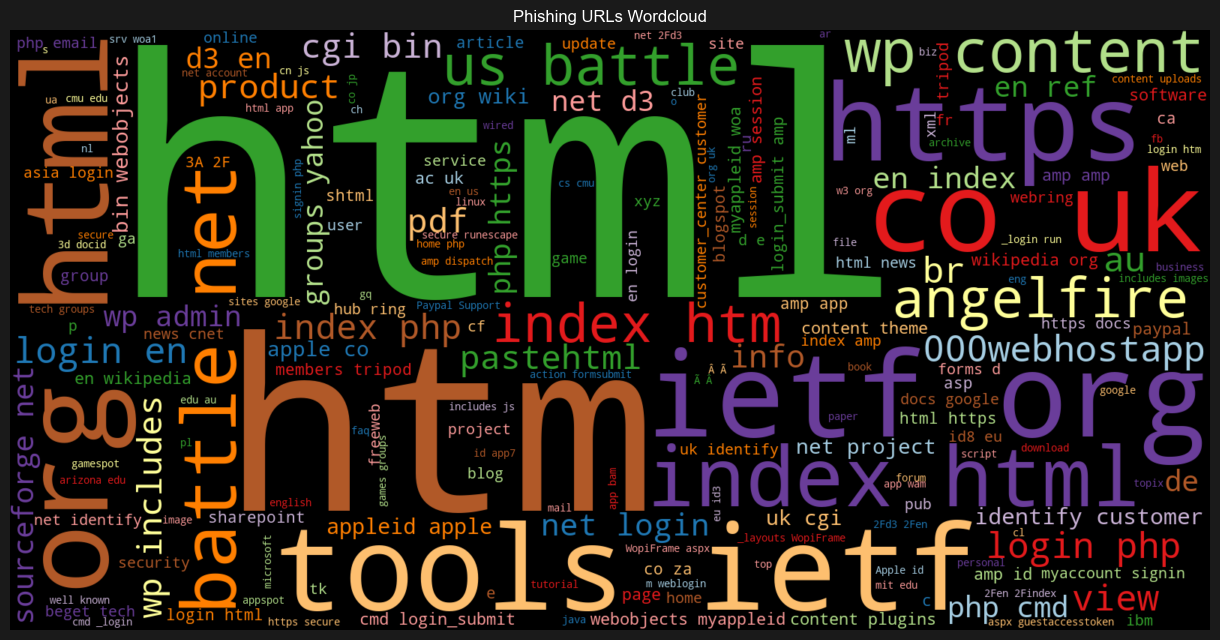

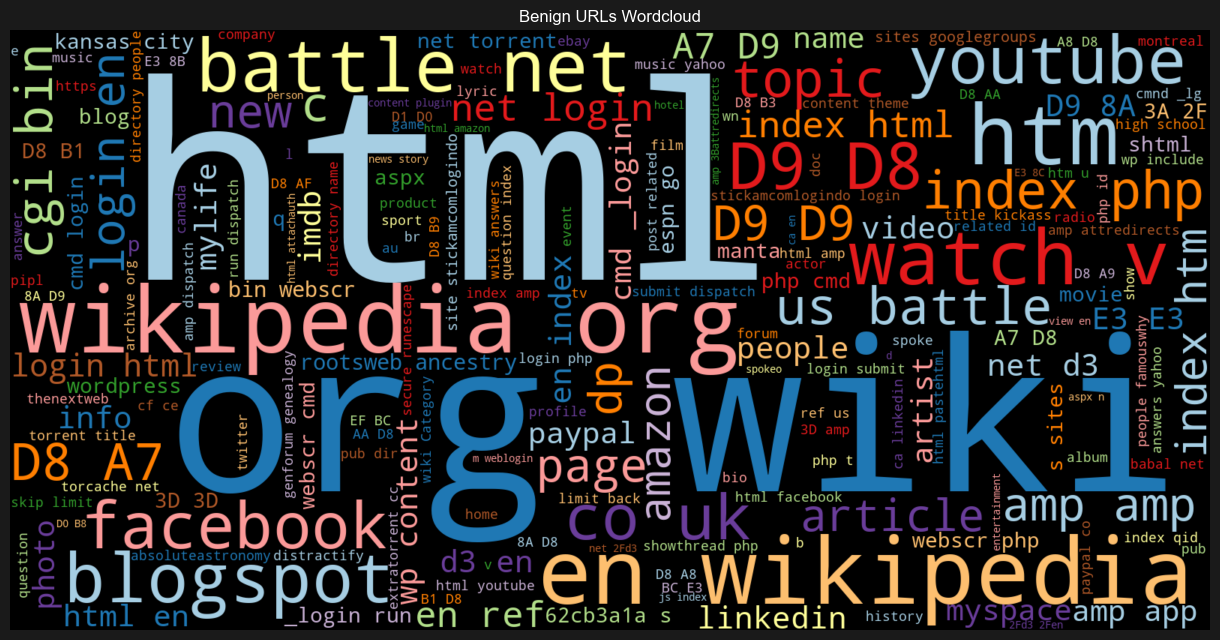

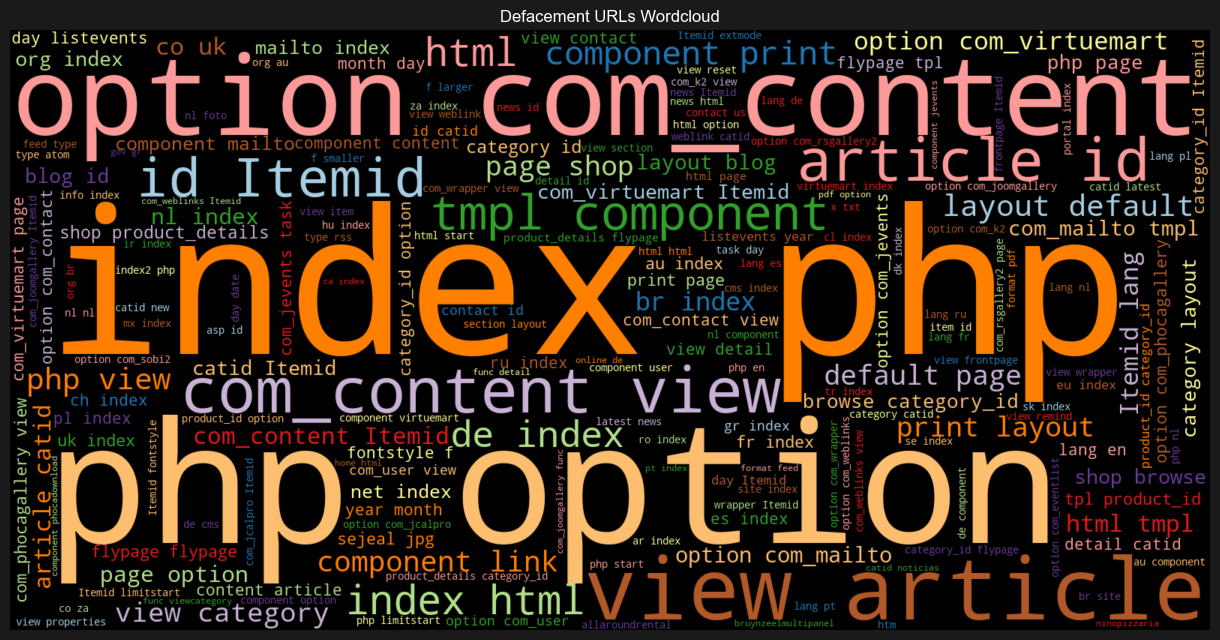

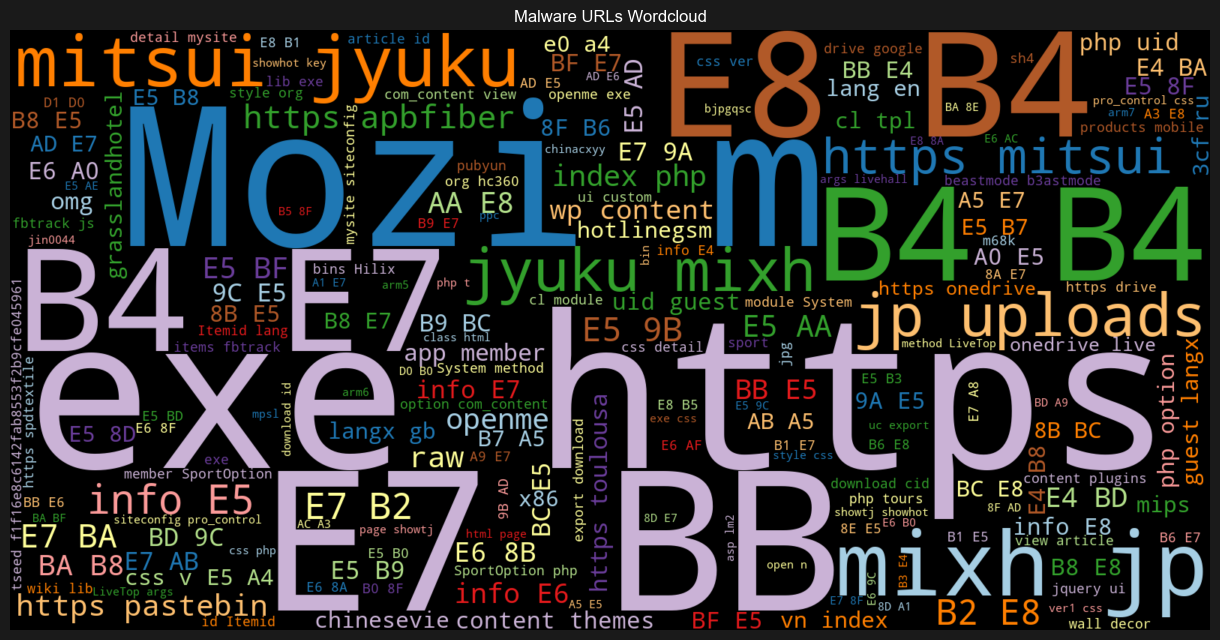

In [23]:
# 6. Visualizing Word Clouds

def plot_wordcloud(data_subset, title):
    """Plot a word cloud for a given subset of data."""
    combined_urls = " ".join(i for i in data_subset.url if isinstance(i, str))
    wordcloud = WordCloud(width=1600, height=800, colormap='Paired',
                          background_color='black').generate(combined_urls)
    plt.figure(figsize=(12, 14), facecolor='k')
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis("off")
    plt.title(title, color='white')
    plt.tight_layout(pad=0)
    plt.show()

# Plot wordclouds for each class
classes = data['type'].unique()
for cls in classes:
    subset = data[data.type == cls]
    plot_wordcloud(subset, f"{cls.capitalize()} URLs Wordcloud")

# *This will display word clouds for each class (`benign`, `malicious`, etc.), highlighting the most frequent words in the URLs.*

## 7. Feature Engineering

Menerapkan berbagai fungsi feature engineering untuk mengekstrak fitur dari URL.

In [24]:
# 7. Feature Engineering
print("\nStarting feature engineering...")

# Apply feature engineering functions
data['secure_http'] = data['url'].apply(secure_http)
data['url_length'] = data['url'].apply(url_length)
data['find_subdomain'] = data['url'].apply(find_subdomain)
data['tld'] = data['url'].apply(get_tld_func)
data['domain_token_count'] = data['url'].apply(domain_token_count)
data['hostname_length'] = data['url'].apply(hostname_length)
data['root_domain'] = data['url'].apply(extract_root_domain)
data['count.'] = data['url'].apply(count_dot)
data['count_dir'] = data['url'].apply(no_of_dir)
data['count%'] = data['url'].apply(
    lambda x: x.count('%') if isinstance(x, str) else 0)
data['count?'] = data['url'].apply(
    lambda x: x.count('?') if isinstance(x, str) else 0)
data['count-'] = data['url'].apply(lambda x: x.count('-')
                                   if isinstance(x, str) else 0)
data['count='] = data['url'].apply(
    lambda x: x.count('=') if isinstance(x, str) else 0)
data['count-digits'] = data['url'].apply(digit_count)
data['count-letters'] = data['url'].apply(letter_count)
data['fd_length'] = data['url'].apply(fd_length)
data['path_length'] = data['url'].apply(path_length)
data['NumQueryComponents'] = data['url'].apply(num_query_components)
data['short_url'] = data['url'].apply(shortening_service)
data['abnormal_url'] = data['url'].apply(abnormal_url)
data['sus_url'] = data['url'].apply(suspicious_words)
data['use_of_ip'] = data['url'].apply(having_ip_address)
data['contains_file'] = data['url'].apply(contains_file)

# Apply is_trusted_tld function
data['is_trusted_tld'] = data['url'].apply(
    lambda url: is_trusted_tld(url, weight=10, https_bonus=5))

# Add a combined feature
data['trusted_and_https'] = data['is_trusted_tld'] * data['secure_http']


Starting feature engineering...


## 8. Hash Encoding untuk Kolom 'tld'

Mengubah data kategorikal `tld` menjadi numerik menggunakan hash encoding untuk memastikan kompatibilitas dengan XGBoost.

In [25]:
# 8. Hash Encoding for 'tld' Column

def hash_encoding(value, hash_function=hashlib.md5, base=16, mod=10**9):
    """
    Function to hash encode a value.
    
    Parameters:
    - value: The categorical value to hash encode.
    - hash_function: Hash function from hashlib to use (default: hashlib.md5).
    - base: Base to interpret the hash value as (default: 16 for hexadecimal).
    - mod: Modulo value to limit the size of the hashed integer.
    
    Returns:
    - int: The hashed numerical representation of the value.
    """
    try:
        # Hash the value using the specified hash function
        hashed_value = hash_function(value.encode()).hexdigest()
        # Convert the hash to an integer and apply modulo to limit size
        return int(hashed_value, base) % mod
    except Exception as e:
        print(f"Error encoding value '{value}': {e}")
        return 0

# Apply hash encoding to the 'tld' column
data['tld_hashed'] = data['tld'].apply(lambda x: hash_encoding(x))

# Convert 'tld_hashed' to integer type explicitly
data['tld_hashed'] = data['tld_hashed'].astype(int)

## 9. Seleksi Fitur

Memilih fitur-fitur yang relevan untuk pelatihan model.

In [26]:
# 9. Feature Selection

# Update feature_columns to include 'tld_hashed' and exclude 'tld'
feature_columns = [
    'secure_http', 'url_length', 'find_subdomain', 'tld_hashed', 'domain_token_count',
    'hostname_length', 'root_domain', 'count.', 'count_dir', 'count%', 'count?',
    'count-', 'count=', 'count-digits', 'count-letters', 'fd_length',
    'path_length', 'NumQueryComponents', 'short_url', 'abnormal_url',
    'sus_url', 'use_of_ip', 'contains_file', 'is_trusted_tld',
    'trusted_and_https'
]

# Select the relevant features for model training
X = data[feature_columns]
y = data['type']

print("\nFeature matrix X shape:", X.shape)
print("Target vector y distribution:")
print(y.value_counts())


Feature matrix X shape: (652528, 25)
Target vector y distribution:
type
benign        429440
defacement     96457
phishing       94111
malware        32520
Name: count, dtype: int64


## 10. Label Encoding

Mengubah label target menjadi format numerik menggunakan `LabelEncoder`.

In [27]:
# 10. Label Encoding

print("\nEncoding target labels...")

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
print("Classes found and their corresponding encoded labels:")
for idx, class_label in enumerate(label_encoder.classes_):
    print(f"{class_label}: {idx}")

# Save the label encoder for future use
dump(label_encoder, LABEL_ENCODER_PATH)
print(f"Label encoder saved to {LABEL_ENCODER_PATH}")


Encoding target labels...
Classes found and their corresponding encoded labels:
benign: 0
defacement: 1
malware: 2
phishing: 3
Label encoder saved to ./models/label_encoder.pkl


## 11. Menangani Nilai Hilang untuk Fitur Kategorikal

Mengisi nilai yang hilang pada fitur-fitur kategorikal sebelum melakukan encoding.

In [28]:
# 11. Handling Missing Values for Categorical Features

# Mengisi nilai null di fitur kategorikal yang akan di-encode
# Karena 'tld' sudah di-hash, kita hanya perlu mengisi 'find_subdomain' dan 'root_domain'
X[['find_subdomain', 'root_domain']] = X[['find_subdomain', 'root_domain']].fillna('missing')

# Verifikasi tidak ada nilai null di kolom kategorikal
print("\nNull values after filling:")
print(X[['find_subdomain', 'root_domain']].isnull().sum())


Null values after filling:
find_subdomain    0
root_domain       0
dtype: int64


/var/folders/2t/4pk9n9cn4vq4vq2kybwvrbqc0000gn/T/ipykernel_34805/2624396287.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X[['find_subdomain', 'root_domain']] = X[['find_subdomain', 'root_domain']].fillna('missing')


## 12. Encoding Fitur Kategorikal dengan TargetEncoder

Menggunakan `TargetEncoder` untuk mengubah fitur kategorikal menjadi numerik berdasarkan target.

In [29]:
# 12. Encoding Categorical Features with TargetEncoder

# Initialize the TargetEncoder dengan kolom yang akan di-encode
# 'tld_hashed' adalah numerik, jadi tidak perlu di-encode lagi
encoder = TargetEncoder(cols=['find_subdomain', 'root_domain'])

# Fit encoder pada data training
encoder.fit(X, y_encoded)

# Transform data training
X_encoded = encoder.transform(X)

print("\nFeature engineering completed. Here's a preview:")
print(X_encoded.head())

# Save the encoder for future use
dump(encoder, ENCODER_PATH)
print(f"Target encoder saved to {ENCODER_PATH}")


Feature engineering completed. Here's a preview:
   secure_http  url_length  find_subdomain  tld_hashed  domain_token_count  \
0            0          16        0.420859   644138238                   3   
1            0          35        0.420859   754754640                   2   
2            0          31        0.420859   326125624                   2   
3            0          81        1.478495   515781161                   3   
4            0         228        0.420859   355660260                   2   

   hostname_length   root_domain  count.  count_dir  count%  ...  fd_length  \
0               16  9.819996e-01       2          0       0  ...          0   
1               11  2.096854e-10       2          2       0  ...          5   
2               14  5.916742e-01       2          3       0  ...          7   
3               21  9.651076e-01       3          1       0  ...          9   
4               23  9.999122e-01       2          1       0  ...          9   

   pat

## 13. Cross-Validation dengan XGBoost

Melakukan cross-validation dengan model XGBoost untuk mengevaluasi performa model.


Starting cross-validation with XGBoost classifier...

--- Fold 1 ---
Class distribution before oversampling:
0    375928
1     84266
3     82279
2     28489
Name: count, dtype: int64
Class distribution after oversampling:
3    375928
0    375928
1    375928
2    375928
Name: count, dtype: int64


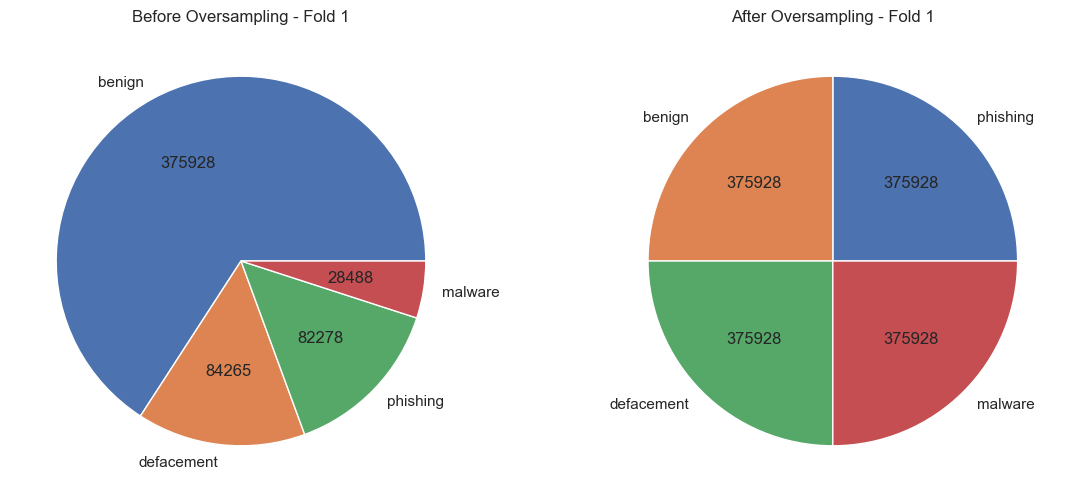

/Users/kidman/.pyenv/versions/3.10.15/lib/python3.10/site-packages/xgboost/core.py:158: UserWarning: [03:51:57] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)



Classification Report:
              precision    recall  f1-score   support

      benign       1.00      0.99      0.99     53512
  defacement       0.99      1.00      0.99     12191
     malware       0.97      0.99      0.98      4031
    phishing       0.95      0.97      0.96     11832

    accuracy                           0.99     81566
   macro avg       0.98      0.99      0.98     81566
weighted avg       0.99      0.99      0.99     81566

Accuracy: 0.988


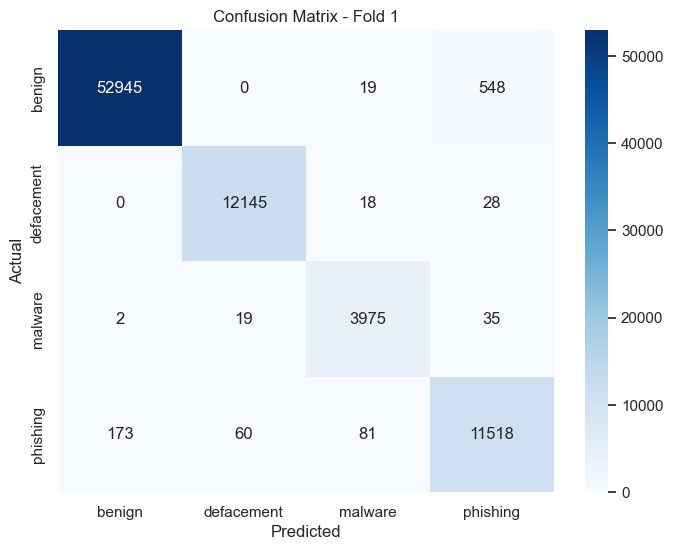

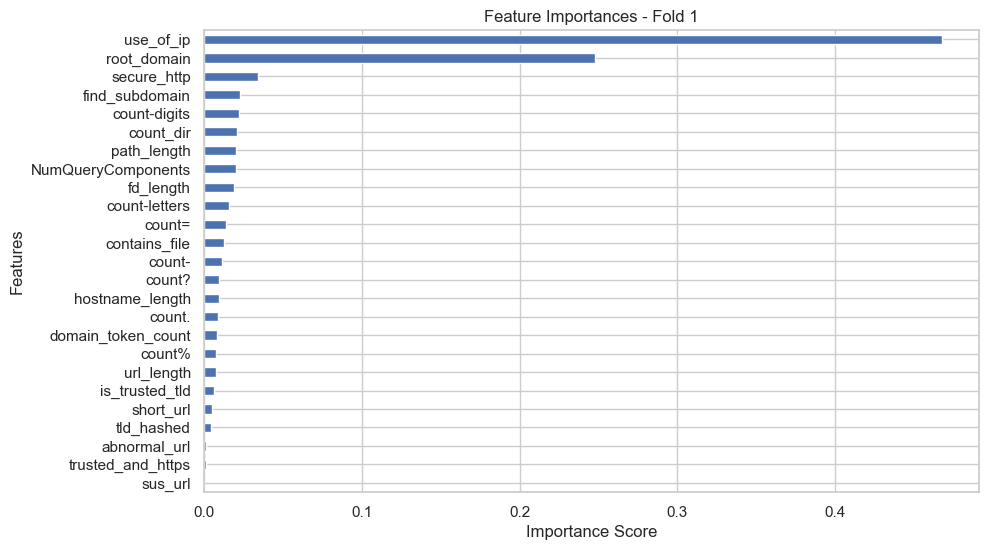


--- Fold 2 ---
Class distribution before oversampling:
0    375637
1     84536
3     82271
2     28518
Name: count, dtype: int64
Class distribution after oversampling:
0    375637
1    375637
3    375637
2    375637
Name: count, dtype: int64


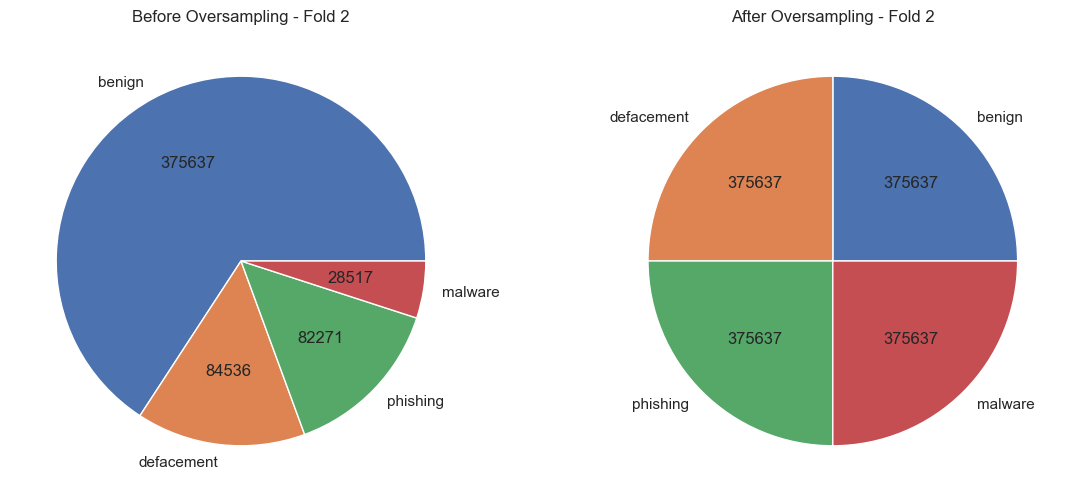

/Users/kidman/.pyenv/versions/3.10.15/lib/python3.10/site-packages/xgboost/core.py:158: UserWarning: [03:52:13] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)



Classification Report:
              precision    recall  f1-score   support

      benign       1.00      0.99      0.99     53803
  defacement       0.99      1.00      1.00     11921
     malware       0.97      0.98      0.98      4002
    phishing       0.95      0.97      0.96     11840

    accuracy                           0.99     81566
   macro avg       0.98      0.99      0.98     81566
weighted avg       0.99      0.99      0.99     81566

Accuracy: 0.988


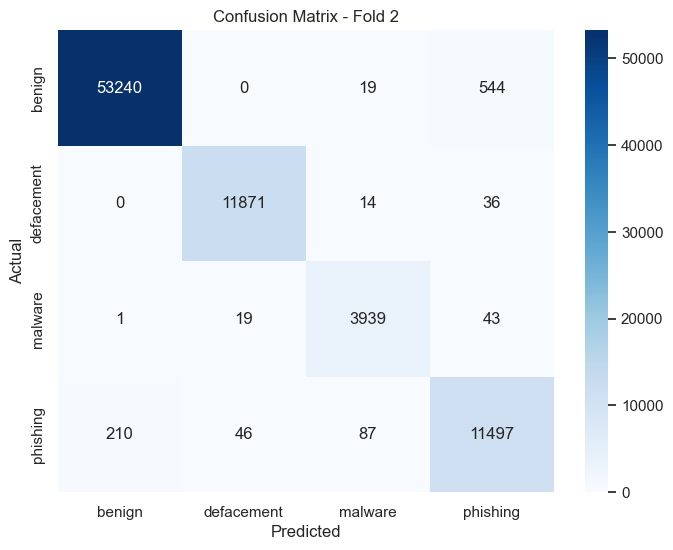

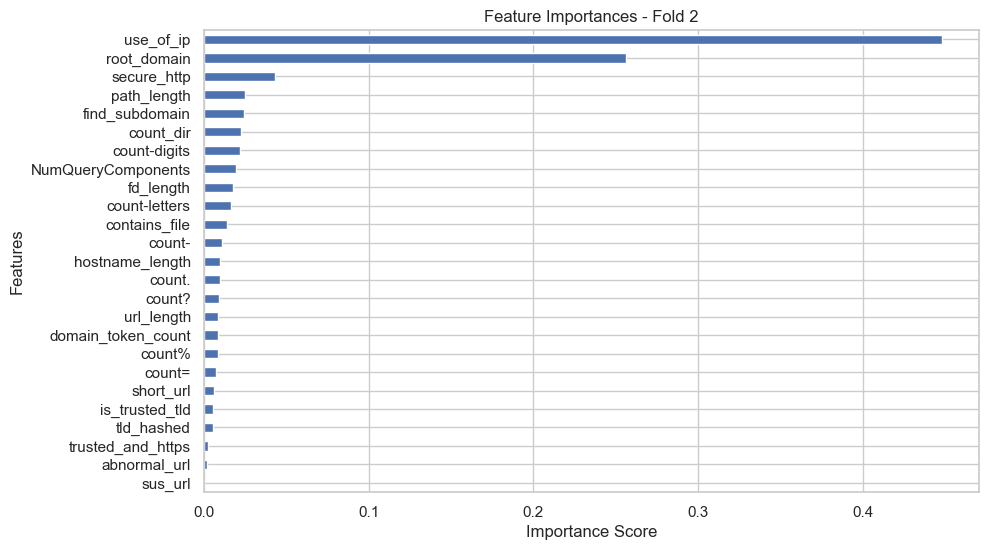


--- Fold 3 ---
Class distribution before oversampling:
0    375541
1     84546
3     82453
2     28422
Name: count, dtype: int64
Class distribution after oversampling:
3    375541
0    375541
1    375541
2    375541
Name: count, dtype: int64


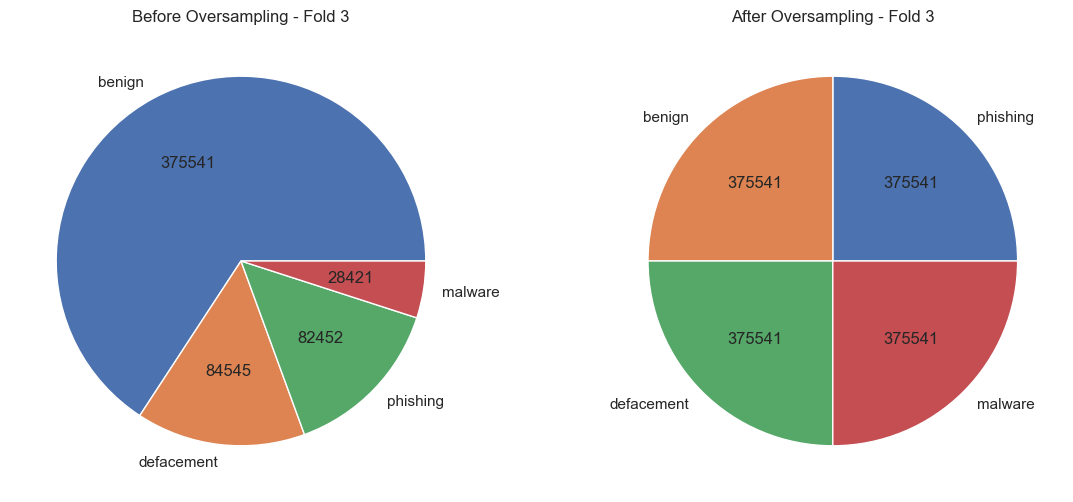

/Users/kidman/.pyenv/versions/3.10.15/lib/python3.10/site-packages/xgboost/core.py:158: UserWarning: [03:52:30] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)



Classification Report:
              precision    recall  f1-score   support

      benign       1.00      0.99      0.99     53899
  defacement       1.00      1.00      1.00     11911
     malware       0.97      0.99      0.98      4098
    phishing       0.95      0.97      0.96     11658

    accuracy                           0.99     81566
   macro avg       0.98      0.99      0.98     81566
weighted avg       0.99      0.99      0.99     81566

Accuracy: 0.988


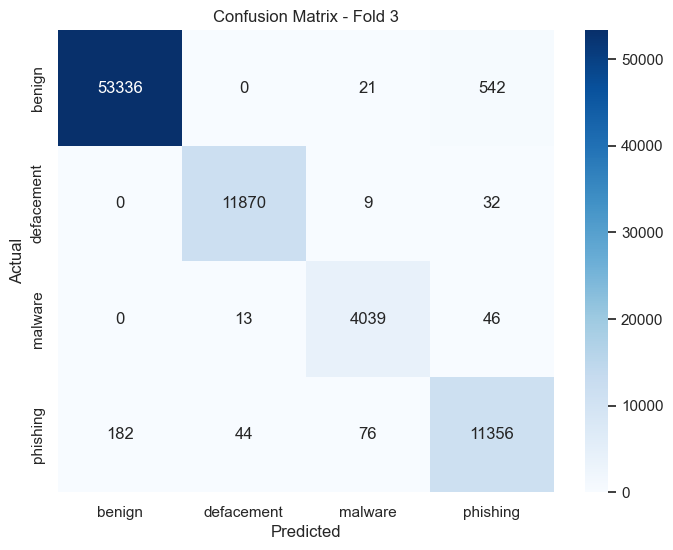

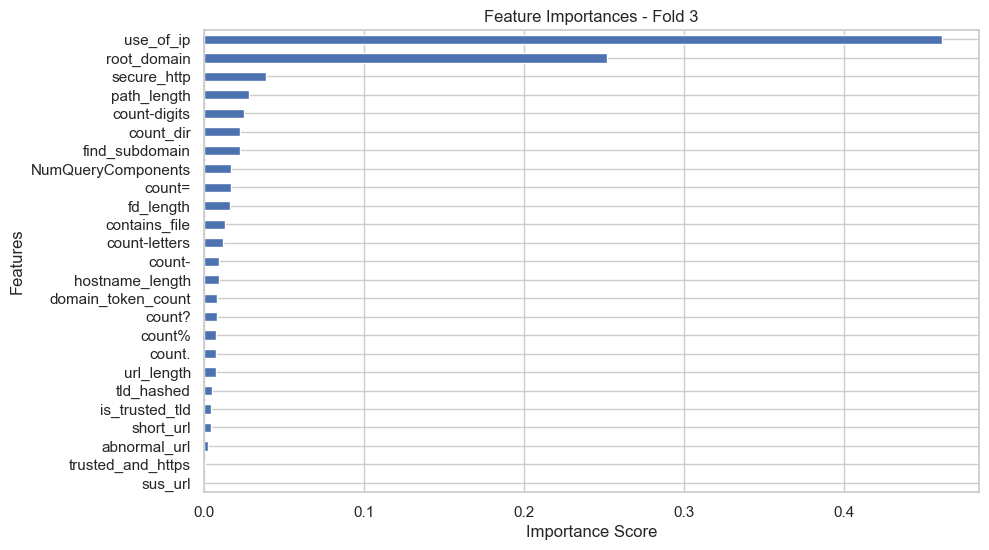


--- Fold 4 ---
Class distribution before oversampling:
0    375605
1     84453
3     82419
2     28485
Name: count, dtype: int64
Class distribution after oversampling:
3    375605
0    375605
1    375605
2    375605
Name: count, dtype: int64


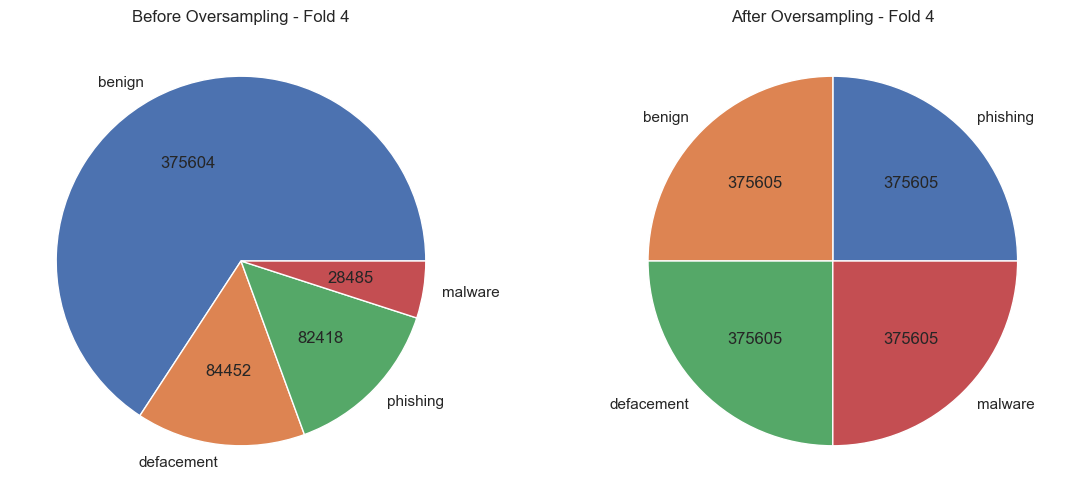

/Users/kidman/.pyenv/versions/3.10.15/lib/python3.10/site-packages/xgboost/core.py:158: UserWarning: [03:52:49] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)



Classification Report:
              precision    recall  f1-score   support

      benign       1.00      0.99      0.99     53835
  defacement       0.99      1.00      1.00     12004
     malware       0.97      0.99      0.98      4035
    phishing       0.95      0.97      0.96     11692

    accuracy                           0.99     81566
   macro avg       0.98      0.99      0.98     81566
weighted avg       0.99      0.99      0.99     81566

Accuracy: 0.988


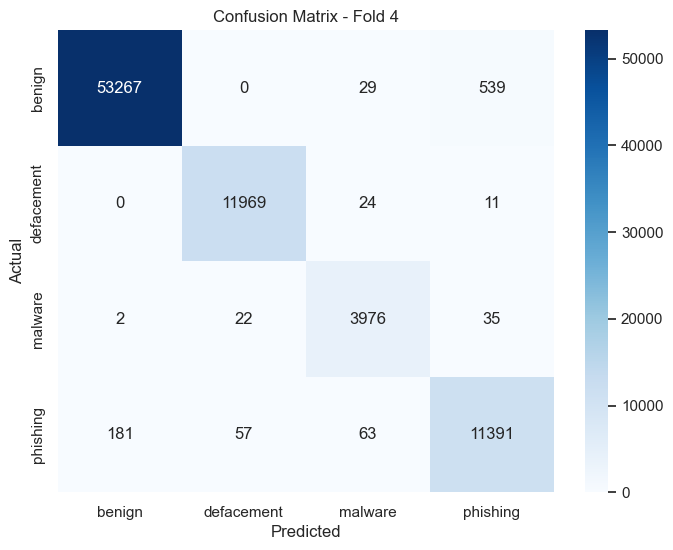

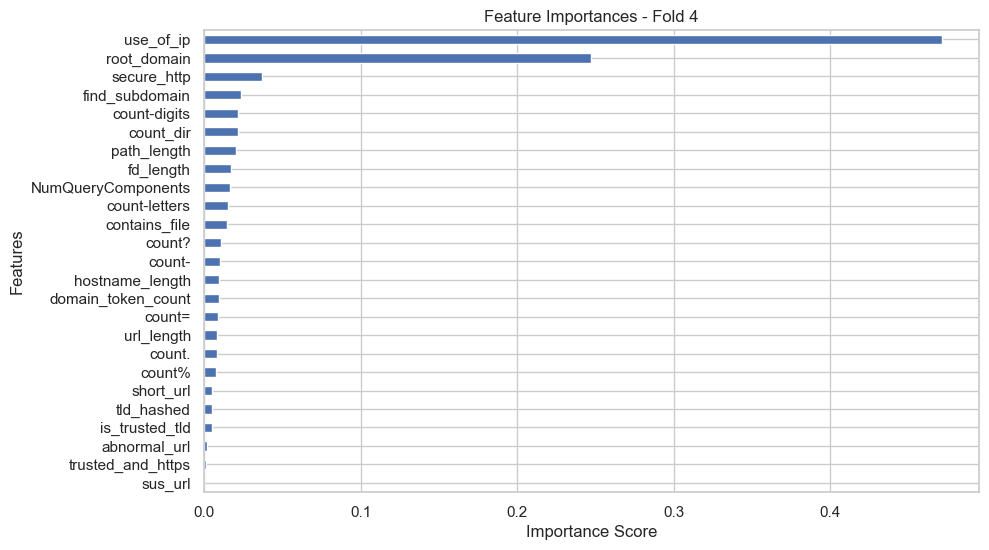


--- Fold 5 ---
Class distribution before oversampling:
0    376078
1     84090
3     82317
2     28477
Name: count, dtype: int64
Class distribution after oversampling:
3    376078
0    376078
1    376078
2    376078
Name: count, dtype: int64


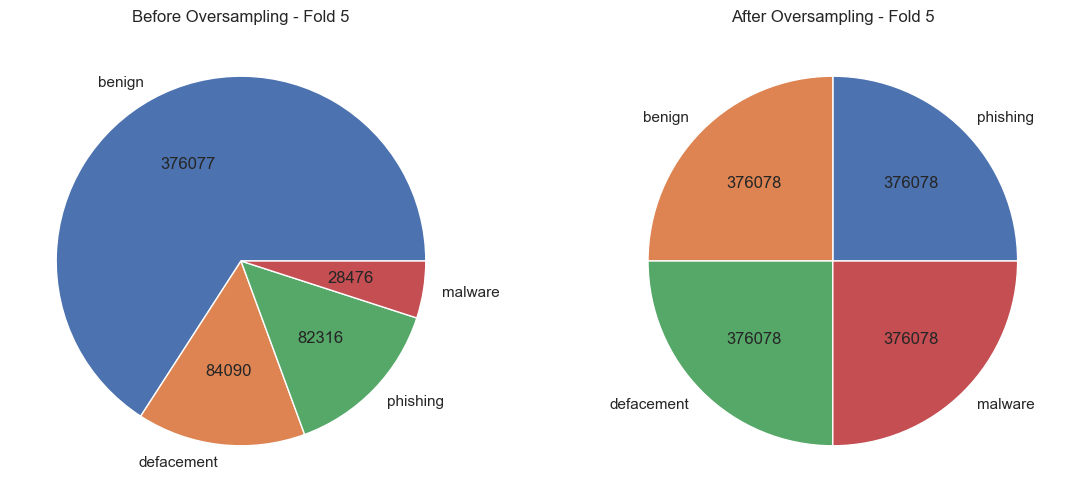

/Users/kidman/.pyenv/versions/3.10.15/lib/python3.10/site-packages/xgboost/core.py:158: UserWarning: [03:53:08] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)



Classification Report:
              precision    recall  f1-score   support

      benign       1.00      0.99      0.99     53362
  defacement       0.99      1.00      0.99     12367
     malware       0.97      0.99      0.98      4043
    phishing       0.95      0.97      0.96     11794

    accuracy                           0.99     81566
   macro avg       0.98      0.99      0.98     81566
weighted avg       0.99      0.99      0.99     81566

Accuracy: 0.988


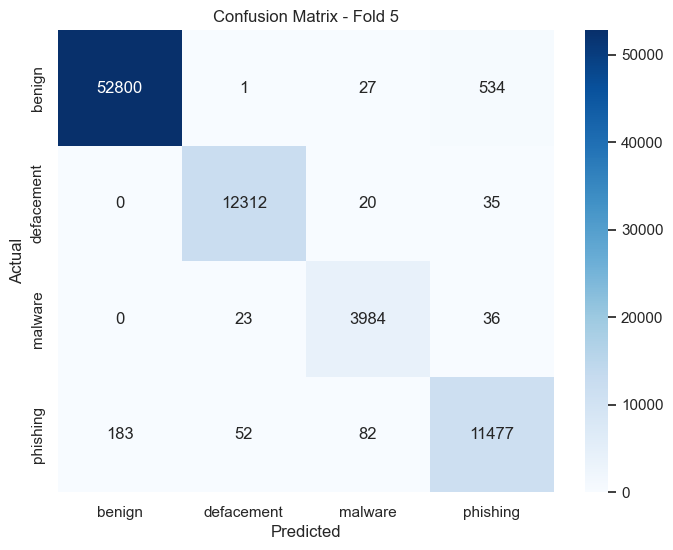

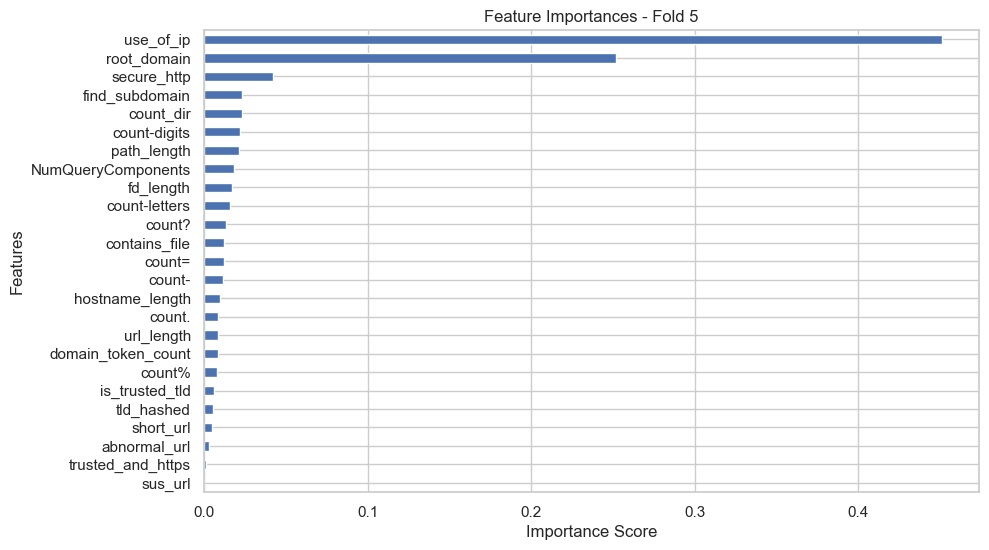


--- Fold 6 ---
Class distribution before oversampling:
0    375798
1     84428
3     82267
2     28469
Name: count, dtype: int64
Class distribution after oversampling:
3    375798
0    375798
1    375798
2    375798
Name: count, dtype: int64


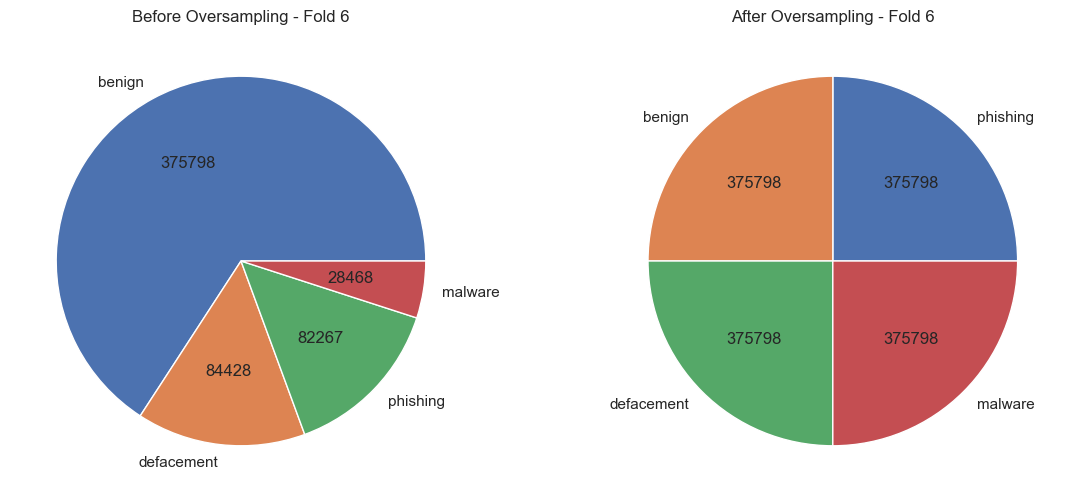

/Users/kidman/.pyenv/versions/3.10.15/lib/python3.10/site-packages/xgboost/core.py:158: UserWarning: [03:53:28] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)



Classification Report:
              precision    recall  f1-score   support

      benign       1.00      0.99      0.99     53642
  defacement       0.99      1.00      1.00     12029
     malware       0.98      0.98      0.98      4051
    phishing       0.95      0.97      0.96     11844

    accuracy                           0.99     81566
   macro avg       0.98      0.99      0.98     81566
weighted avg       0.99      0.99      0.99     81566

Accuracy: 0.988


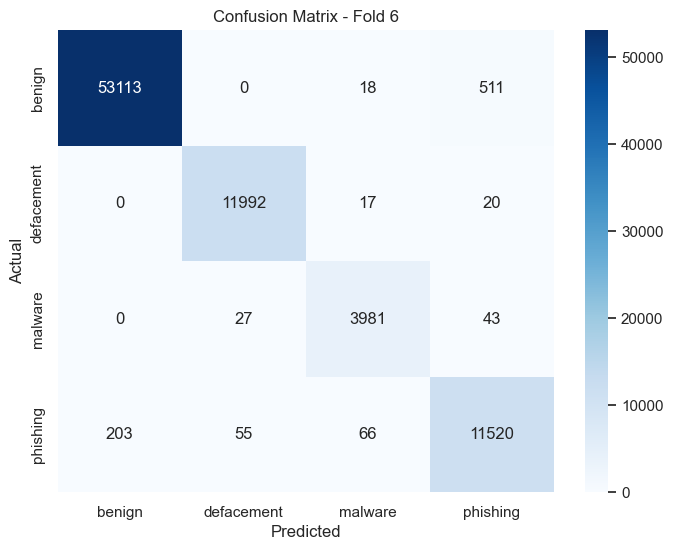

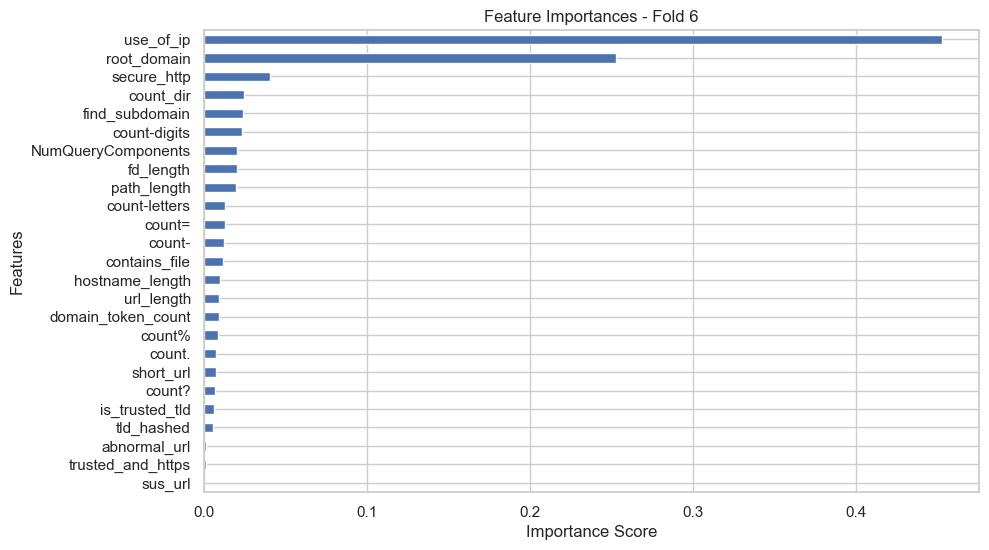


--- Fold 7 ---
Class distribution before oversampling:
0    375638
1     84431
3     82457
2     28436
Name: count, dtype: int64
Class distribution after oversampling:
3    375638
0    375638
1    375638
2    375638
Name: count, dtype: int64


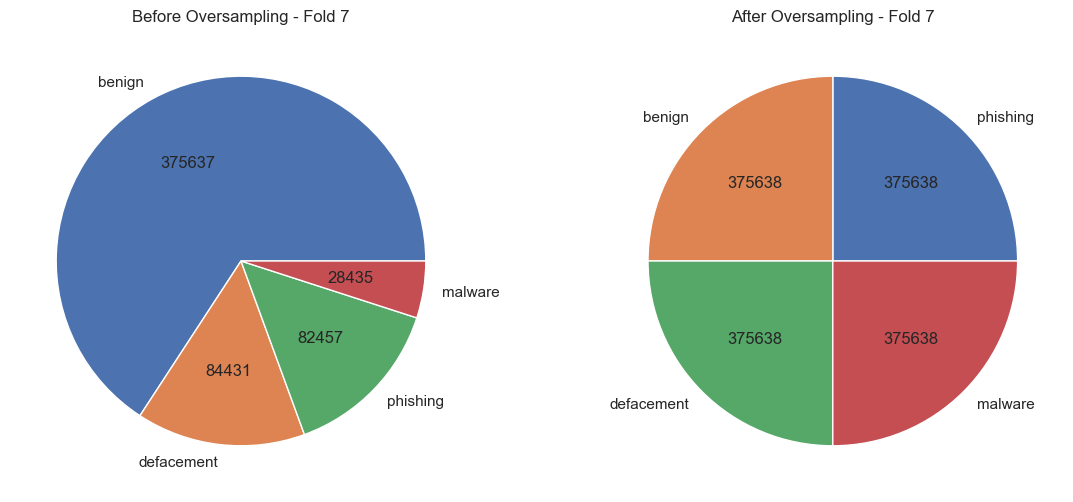

/Users/kidman/.pyenv/versions/3.10.15/lib/python3.10/site-packages/xgboost/core.py:158: UserWarning: [03:53:49] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)



Classification Report:
              precision    recall  f1-score   support

      benign       1.00      0.99      0.99     53802
  defacement       0.99      1.00      0.99     12026
     malware       0.97      0.99      0.98      4084
    phishing       0.95      0.97      0.96     11654

    accuracy                           0.99     81566
   macro avg       0.98      0.99      0.98     81566
weighted avg       0.99      0.99      0.99     81566

Accuracy: 0.988


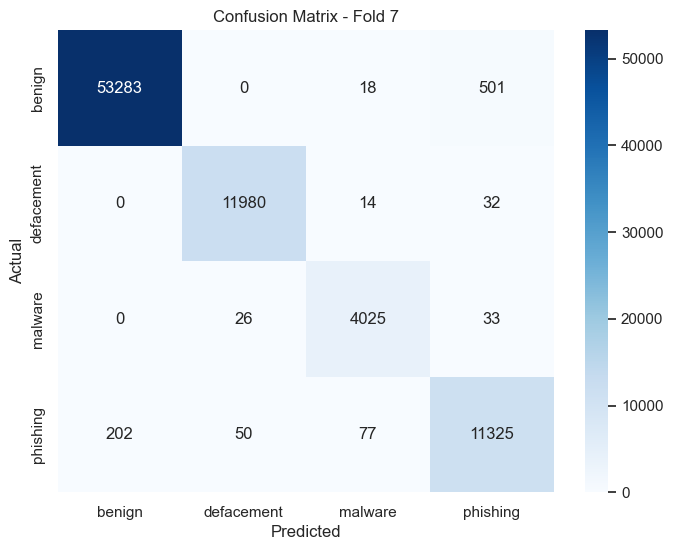

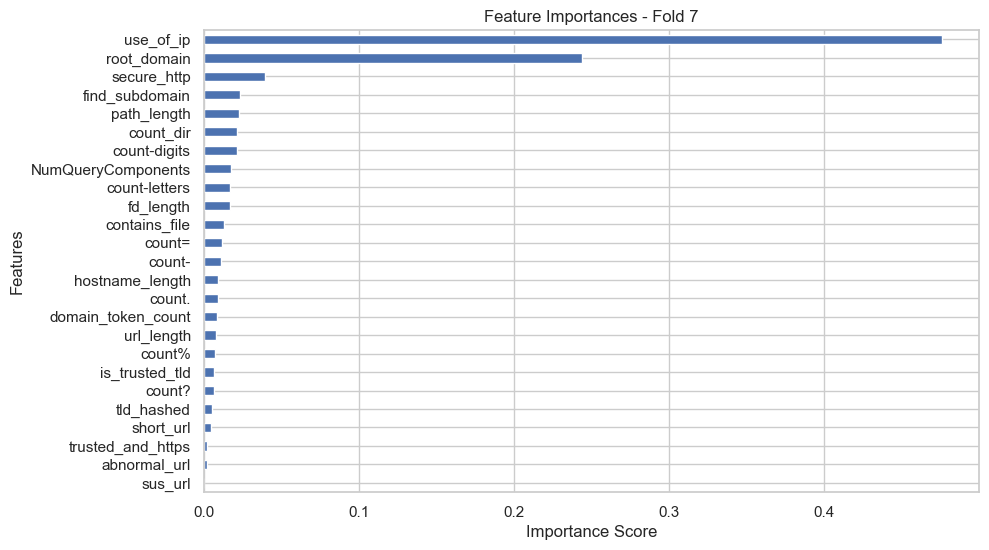


--- Fold 8 ---
Class distribution before oversampling:
0    375855
1     84449
3     82314
2     28344
Name: count, dtype: int64
Class distribution after oversampling:
3    375855
0    375855
1    375855
2    375855
Name: count, dtype: int64


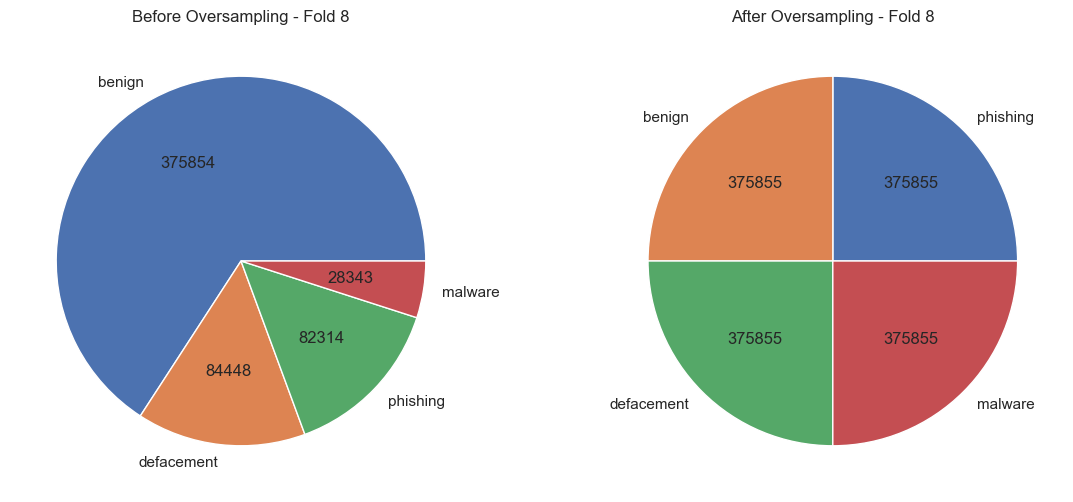

/Users/kidman/.pyenv/versions/3.10.15/lib/python3.10/site-packages/xgboost/core.py:158: UserWarning: [03:54:12] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)



Classification Report:
              precision    recall  f1-score   support

      benign       1.00      0.99      0.99     53585
  defacement       0.99      1.00      1.00     12008
     malware       0.98      0.98      0.98      4176
    phishing       0.95      0.97      0.96     11797

    accuracy                           0.99     81566
   macro avg       0.98      0.99      0.98     81566
weighted avg       0.99      0.99      0.99     81566

Accuracy: 0.988


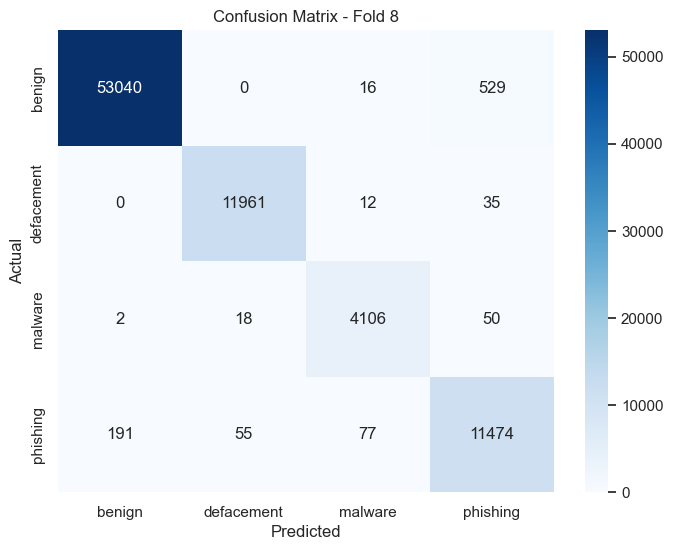

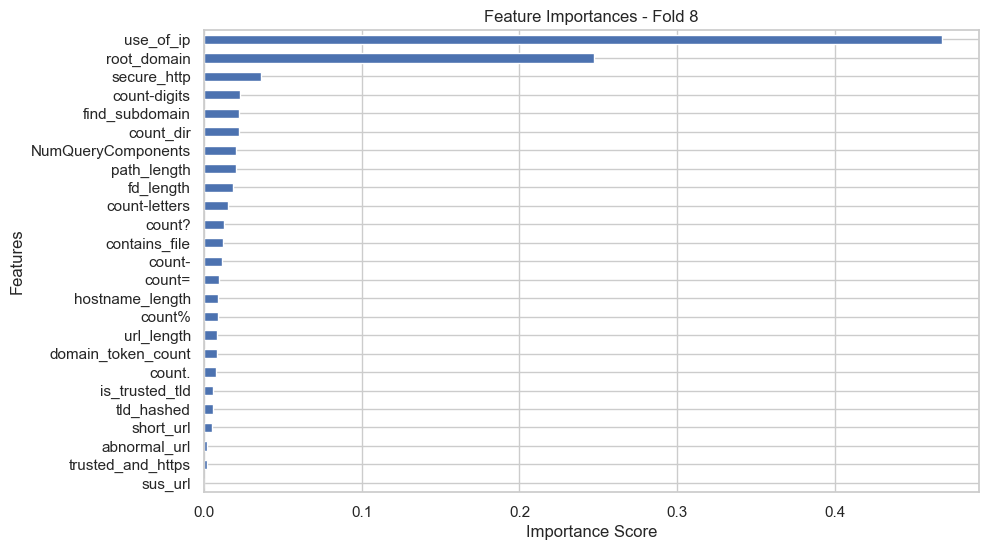

In [30]:
# 13. Cross-Validation with XGBoost

print("\nStarting cross-validation with XGBoost classifier...")

# Initialize k-fold cross-validator
num_folds = 8
kf = KFold(n_splits=num_folds, shuffle=True, random_state=42)

# Lists to store metrics
accuracy_scores = []
confusion_matrices = []
feature_importances_list = []

fold_number = 1

for train_index, test_index in kf.split(X_encoded, y_encoded):
    print(f"\n--- Fold {fold_number} ---")

    X_train_fold, X_test_fold = X_encoded.iloc[train_index], X_encoded.iloc[test_index]
    y_train_fold, y_test_fold = y_encoded[train_index], y_encoded[test_index]

    # Initialize RandomOverSampler
    ros = RandomOverSampler(sampling_strategy="not majority", random_state=42)
    X_train_ros, y_train_ros = ros.fit_resample(X_train_fold, y_train_fold)

    # Store class distributions
    class_distribution_before = pd.Series(y_train_fold).value_counts()
    class_distribution_after = pd.Series(y_train_ros).value_counts()
    print("Class distribution before oversampling:")
    print(class_distribution_before)
    print("Class distribution after oversampling:")
    print(class_distribution_after)

    # Plot class distribution before and after oversampling
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

    # Before Oversampling
    labels_before = label_encoder.inverse_transform(
        class_distribution_before.index)
    ax1.pie(class_distribution_before, labels=labels_before,
            autopct=lambda p: f'{int(p * class_distribution_before.sum() / 100)}')
    ax1.set_title(f"Before Oversampling - Fold {fold_number}")

    # After Oversampling
    labels_after = label_encoder.inverse_transform(
        class_distribution_after.index)
    ax2.pie(class_distribution_after, labels=labels_after,
            autopct=lambda p: f'{int(p * class_distribution_after.sum() / 100)}')
    ax2.set_title(f"After Oversampling - Fold {fold_number}")

    plt.show()

    # Initialize XGBoost Classifier tanpa use_label_encoder
    xgb_model = XGBClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=6,
        random_state=42,
        eval_metric='mlogloss',  # Pastikan eval_metric sesuai dengan kebutuhan
        use_label_encoder=False,
        n_jobs=-1
    )

    # Train the model
    xgb_model.fit(X_train_ros, y_train_ros)

    # Predict on test fold
    y_pred_xgb = xgb_model.predict(X_test_fold)

    # Confusion Matrix
    cm_fold = metrics.confusion_matrix(
        y_test_fold, y_pred_xgb, labels=np.arange(len(label_encoder.classes_)))
    confusion_matrices.append(cm_fold)

    # Classification Report
    print("\nClassification Report:")
    print(metrics.classification_report(y_test_fold,
          y_pred_xgb, target_names=label_encoder.classes_))

    # Accuracy Score
    score = metrics.accuracy_score(y_test_fold, y_pred_xgb)
    print(f"Accuracy: {score:.3f}")
    accuracy_scores.append(score)

    # Confusion Matrix Heatmap
    cm_df_fold = pd.DataFrame(cm_fold, index=label_encoder.classes_,
                              columns=label_encoder.classes_)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm_df_fold, annot=True, fmt="d", cmap='Blues')
    plt.title(f'Confusion Matrix - Fold {fold_number}')
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.show()

    # Feature Importances
    feat_importances = pd.Series(
        xgb_model.feature_importances_, index=X_train_ros.columns)
    feat_importances.sort_values(ascending=True).plot(
        kind="barh", figsize=(10, 6))
    plt.title(f'Feature Importances - Fold {fold_number}')
    plt.xlabel('Importance Score')
    plt.ylabel('Features')
    plt.show()

    # Store feature importances
    feature_importances_list.append(feat_importances)

    fold_number += 1

## 14. Ringkasan Metrik Cross-Validation

Menghitung rata-rata akurasi dan mengagregasi feature importances dari semua fold cross-validation.


Average Accuracy Across 8 Folds: 0.988


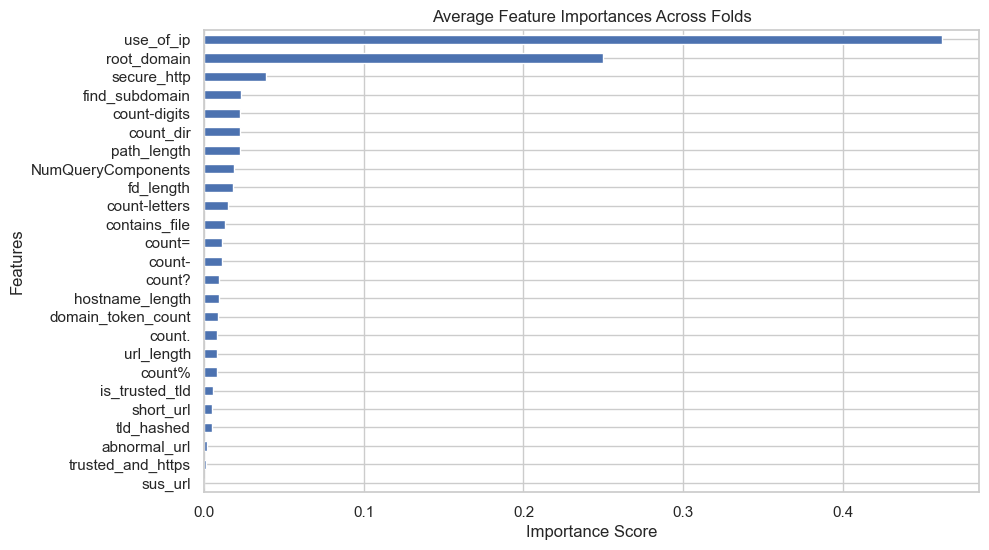

In [31]:
# 14. Summary of Cross-Validation Metrics

# Average Accuracy
average_accuracy = np.mean(accuracy_scores)
print(f"\nAverage Accuracy Across {num_folds} Folds: {average_accuracy:.3f}")

# Aggregate Feature Importances
average_feature_importances = pd.concat(
    feature_importances_list, axis=1).mean(axis=1).sort_values()
average_feature_importances.plot(kind="barh", figsize=(10, 6))
plt.title('Average Feature Importances Across Folds')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

## 15. Pelatihan Model Final

Melatih model XGBoost akhir pada seluruh dataset setelah oversampling.


Training final model on the entire dataset...

Class Distribution After Oversampling:
3    429440
0    429440
1    429440
2    429440
Name: count, dtype: int64
Classes:
['phishing' 'benign' 'defacement' 'malware']


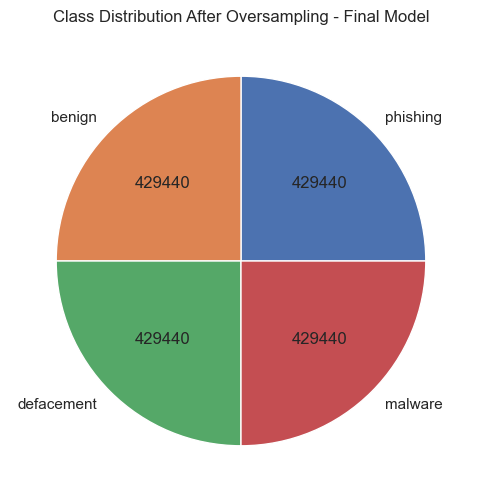


Performing GridSearchCV...
Fitting 5 folds for each of 8 candidates, totalling 40 fits


/Users/kidman/.pyenv/versions/3.10.15/lib/python3.10/site-packages/xgboost/core.py:158: UserWarning: [03:54:42] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/Users/kidman/.pyenv/versions/3.10.15/lib/python3.10/site-packages/xgboost/core.py:158: UserWarning: [03:54:42] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/Users/kidman/.pyenv/versions/3.10.15/lib/python3.10/site-packages/xgboost/core.py:158: UserWarning: [03:54:42] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/Users/kidman/.pyenv/versions/3.10.15/lib/python3.10/site-packages/xgboost/core.py:158: UserWarning: [03:54:42] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" 

[CV] END colsample_bytree=0.8, gamma=0.1, learning_rate=0.01, max_depth=4, min_child_weight=2, n_estimators=100, subsample=0.8; total time= 1.8min
[CV] END colsample_bytree=0.8, gamma=0.1, learning_rate=0.01, max_depth=4, min_child_weight=2, n_estimators=100, subsample=0.8; total time= 1.8min
[CV] END colsample_bytree=0.8, gamma=0.1, learning_rate=0.01, max_depth=4, min_child_weight=2, n_estimators=100, subsample=0.8; total time= 1.8min
[CV] END colsample_bytree=0.8, gamma=0.1, learning_rate=0.01, max_depth=4, min_child_weight=2, n_estimators=100, subsample=0.8; total time= 1.8min
[CV] END colsample_bytree=0.8, gamma=0.1, learning_rate=0.01, max_depth=4, min_child_weight=2, n_estimators=100, subsample=0.8; total time= 1.8min


/Users/kidman/.pyenv/versions/3.10.15/lib/python3.10/site-packages/xgboost/core.py:158: UserWarning: [03:56:28] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/Users/kidman/.pyenv/versions/3.10.15/lib/python3.10/site-packages/xgboost/core.py:158: UserWarning: [03:56:29] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/Users/kidman/.pyenv/versions/3.10.15/lib/python3.10/site-packages/xgboost/core.py:158: UserWarning: [03:56:29] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/Users/kidman/.pyenv/versions/3.10.15/lib/python3.10/site-packages/xgboost/core.py:158: UserWarning: [03:56:29] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" 

[CV] END colsample_bytree=0.8, gamma=0.1, learning_rate=0.01, max_depth=5, min_child_weight=2, n_estimators=100, subsample=0.8; total time= 2.0min
[CV] END colsample_bytree=0.8, gamma=0.1, learning_rate=0.01, max_depth=5, min_child_weight=2, n_estimators=100, subsample=0.8; total time= 2.0min
[CV] END colsample_bytree=0.8, gamma=0.1, learning_rate=0.01, max_depth=5, min_child_weight=2, n_estimators=100, subsample=0.8; total time= 2.0min


/Users/kidman/.pyenv/versions/3.10.15/lib/python3.10/site-packages/xgboost/core.py:158: UserWarning: [03:56:39] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/Users/kidman/.pyenv/versions/3.10.15/lib/python3.10/site-packages/xgboost/core.py:158: UserWarning: [03:56:41] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/Users/kidman/.pyenv/versions/3.10.15/lib/python3.10/site-packages/xgboost/core.py:158: UserWarning: [03:56:41] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


... (14 outputs left out)

[CV] END colsample_bytree=0.8, gamma=0.2, learning_rate=0.1, max_depth=4, min_child_weight=2, n_estimators=100, subsample=0.8; total time= 2.2min
[CV] END colsample_bytree=0.8, gamma=0.2, learning_rate=0.1, max_depth=4, min_child_weight=2, n_estimators=100, subsample=0.8; total time= 2.2min
[CV] END colsample_bytree=0.8, gamma=0.2, learning_rate=0.1, max_depth=4, min_child_weight=2, n_estimators=100, subsample=0.8; total time= 2.3min
[CV] END colsample_bytree=0.8, gamma=0.2, learning_rate=0.1, max_depth=5, min_child_weight=2, n_estimators=100, subsample=0.8; total time= 2.4min
[CV] END colsample_bytree=0.8, gamma=0.2, learning_rate=0.1, max_depth=5, min_child_weight=2, n_estimators=100, subsample=0.8; total time= 2.4min
[CV] END colsample_bytree=0.8, gamma=0.2, learning_rate=0.1, max_depth=5, min_child_weight=2, n_estimators=100, subsample=0.8; total time= 2.4min
[CV] END colsample_bytree=0.8, gamma=0.2, learning_rate=0.1, max_depth=5, min_child_weight=2, n_estimators=100, subsample=0.

/Users/kidman/.pyenv/versions/3.10.15/lib/python3.10/site-packages/xgboost/core.py:158: UserWarning: [04:04:41] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)



Best parameters found:
{'colsample_bytree': 0.8, 'gamma': 0.2, 'learning_rate': 0.1, 'max_depth': 5, 'min_child_weight': 2, 'n_estimators': 100, 'subsample': 0.8}

Best cross-validation score: 0.975


/Users/kidman/.pyenv/versions/3.10.15/lib/python3.10/site-packages/xgboost/core.py:158: UserWarning: [04:05:03] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/Users/kidman/.pyenv/versions/3.10.15/lib/python3.10/site-packages/xgboost/core.py:158: UserWarning: [04:05:26] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


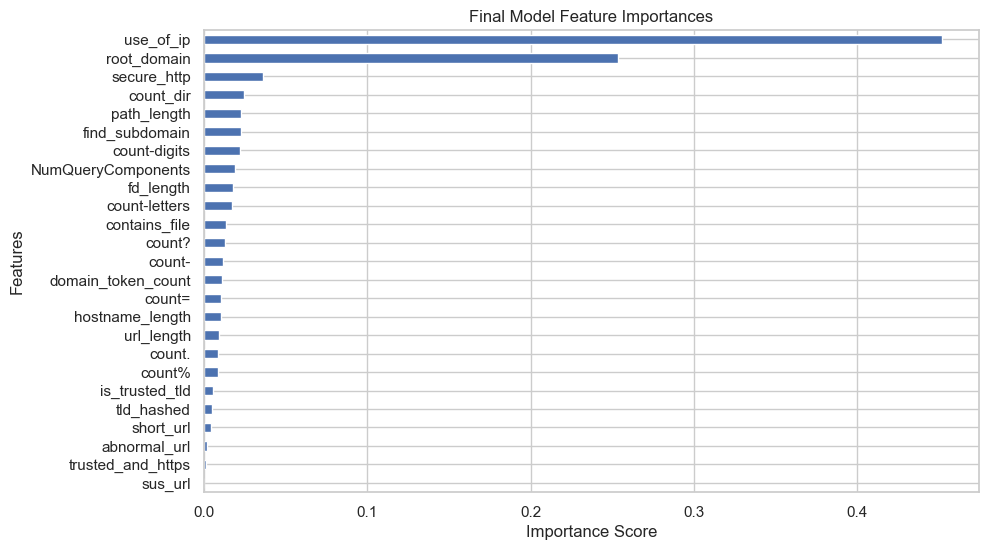

Final XGBoost model saved to ./models/final_xgb_model.pkl


In [32]:
# 15. Training the Final Model
from sklearn.model_selection import GridSearchCV

print("\nTraining final model on the entire dataset...")

# Initialize RandomOverSampler for the entire dataset
ros_final = RandomOverSampler(
    sampling_strategy="not majority", random_state=42)
X_resampled, y_resampled = ros_final.fit_resample(X_encoded, y_encoded)

print("\nClass Distribution After Oversampling:")
class_dist_final = pd.Series(y_resampled).value_counts()
print(class_dist_final)
print("Classes:")
print(label_encoder.inverse_transform(class_dist_final.index))

# Plot final class distribution
plt.figure(figsize=(6, 6))
labels_final = label_encoder.inverse_transform(class_dist_final.index)
plt.pie(class_dist_final, labels=labels_final,
        autopct=lambda p: f'{int(p * class_dist_final.sum() / 100)}')
plt.title("Class Distribution After Oversampling - Final Model")
plt.show()


# param_grid = {
#     'n_estimators': [100],
#     'max_depth': [4, 6, 8],
#     'learning_rate': [0.01, 0.1],
#     'subsample': [0.8],
#     'colsample_bytree': [0.8],
#     'min_child_weight': [1],
#     'gamma': [0, 0.1]  # Minimum loss reduction for split
# }

param_grid = {
    'n_estimators': [100],
    'max_depth': [4, 5],           # Lower max_depth to prevent complex trees
    'learning_rate': [0.01, 0.1],  # Small learning rates for better generalization
    'gamma': [0.1, 0.2],          # Higher gamma values to require meaningful splits
    'subsample': [0.8],           # Use subset of data for each tree
    'colsample_bytree': [0.8],    # Use subset of features for each tree
    'min_child_weight': [2]       # Require more observations per node
}

# Initialize base XGBoost model
base_xgb = XGBClassifier(
    random_state=42,
    eval_metric='mlogloss',
    use_label_encoder=False,
    n_jobs=-1
)

# Initialize GridSearchCV
grid_search = GridSearchCV(
    estimator=base_xgb,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=2
)


print("\nPerforming GridSearchCV...")
grid_search.fit(X_resampled, y_resampled)

# Print best parameters and score
print("\nBest parameters found:")
print(grid_search.best_params_)
print(f"\nBest cross-validation score: {grid_search.best_score_:.3f}")

# Use best model for final training
final_xgb = grid_search.best_estimator_

# Train final model with best parameters
final_xgb.fit(X_resampled, y_resampled)

# Save results to CSV
cv_results = pd.DataFrame(grid_search.cv_results_)
cv_results.to_csv('gridcv_results.csv', index=False)


# Initialize XGBoost Classifier
final_xgb = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    eval_metric='mlogloss',
    use_label_encoder=False,
    n_jobs=-1
)

# Train the final model
final_xgb.fit(X_resampled, y_resampled)

# Feature Importances for Final Model
feat_importances_final = pd.Series(
    final_xgb.feature_importances_, index=X_resampled.columns)
feat_importances_final.sort_values().plot(kind="barh", figsize=(10, 6))
plt.title('Final Model Feature Importances')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

# Save the final model
dump(final_xgb, MODEL_PATH)
print(f"Final XGBoost model saved to {MODEL_PATH}")

## 16. Prediksi pada URL Uji

Menggunakan model akhir untuk memprediksi jenis URL pada daftar URL uji.

In [33]:
# 16. Predicting on Test URLs

print("\nPreparing test URLs for prediction...")

# Daftar URL untuk pengujian (pastikan koma yang hilang telah ditambahkan)
test_urls = [
    'https://www.google.com/info', 'https://www.facebook.com', 'https://www.amazon.com', 'https://www.netflix.com',
    'https://www.reddit.com', 'https://www.youtube.com/', 'https://www.twitter.com', 'https://www.linkedin.com',
    'https://www.instagram.com', 'https://www.microsoft.com', 'https://www.apple.com', 'https://www.github.com',
    'https://www.wikipedia.org', 'https://www.quora.com', 'https://www.pinterest.com', 'https://www.ebay.com',
    'https://www.dropbox.com', 'https://www.paypal.com', 'https://www.salesforce.com', 'https://www.tesla.com',
    "allmusic.com/album/crazy-from-the-heat-r16990",
    "http://peluqueriadeautor.com/index.php?option=com_virtuemart&page=shop.browse&category_id=31&Itemid=70",
    "http://9779.info/%E5%84%BF%E7%AB%A5%E7%AB%8B%E4%BD",
    "http://9779.info/%E5%84%BF%E7%AB%A5%E7%AB%8B%E4%BD",
    "http://alexpay2.beget.tech",
    'http://www.pn-wuppertal.de/links/2-linkseite/5-httpwwwkrebshilfede',
    "https://spada.upnyk.ac.id/login/index.php",
    "https://bima.upnyk.ac.id/"
]

# Konversi URL ke dalam DataFrame
test_data = pd.DataFrame({'url': test_urls})

# Apply feature engineering functions
test_data['secure_http'] = test_data['url'].apply(secure_http)
test_data['url_length'] = test_data['url'].apply(url_length)
test_data['find_subdomain'] = test_data['url'].apply(find_subdomain)
test_data['tld'] = test_data['url'].apply(get_tld_func)
test_data['tld_hashed'] = test_data['tld'].apply(lambda x: hash_encoding(x))
test_data['tld_hashed'] = test_data['tld_hashed'].astype(int)  # Ensure numeric type
test_data['domain_token_count'] = test_data['url'].apply(domain_token_count)
test_data['hostname_length'] = test_data['url'].apply(hostname_length)
test_data['root_domain'] = test_data['url'].apply(extract_root_domain)
test_data['count.'] = test_data['url'].apply(count_dot)
test_data['count_dir'] = test_data['url'].apply(no_of_dir)
test_data['count%'] = test_data['url'].apply(
    lambda x: x.count('%') if isinstance(x, str) else 0)
test_data['count?'] = test_data['url'].apply(
    lambda x: x.count('?') if isinstance(x, str) else 0)
test_data['count-'] = test_data['url'].apply(
    lambda x: x.count('-') if isinstance(x, str) else 0)
test_data['count='] = test_data['url'].apply(
    lambda x: x.count('=') if isinstance(x, str) else 0)
test_data['count-digits'] = test_data['url'].apply(digit_count)
test_data['count-letters'] = test_data['url'].apply(letter_count)
test_data['fd_length'] = test_data['url'].apply(fd_length)
test_data['path_length'] = test_data['url'].apply(path_length)
test_data['NumQueryComponents'] = test_data['url'].apply(num_query_components)
test_data['short_url'] = test_data['url'].apply(shortening_service)
test_data['abnormal_url'] = test_data['url'].apply(abnormal_url)
test_data['sus_url'] = test_data['url'].apply(suspicious_words)
test_data['use_of_ip'] = test_data['url'].apply(having_ip_address)
test_data['contains_file'] = test_data['url'].apply(contains_file)

# Apply is_trusted_tld function
test_data['is_trusted_tld'] = test_data['url'].apply(
    lambda url: is_trusted_tld(url, weight=10, https_bonus=5))

# Add a combined feature
test_data['trusted_and_https'] = test_data['is_trusted_tld'] * \
    test_data['secure_http']

# Select Feature Columns
test_features = test_data[feature_columns]

# Mengisi nilai null di fitur kategorikal yang akan di-encode
# Karena 'tld' sudah di-hash, kita hanya perlu mengisi 'find_subdomain' dan 'root_domain'
test_features[['find_subdomain', 'root_domain']] = test_features[['find_subdomain', 'root_domain']].fillna('missing')


Preparing test URLs for prediction...


/var/folders/2t/4pk9n9cn4vq4vq2kybwvrbqc0000gn/T/ipykernel_34805/32475110.py:69: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test_features[['find_subdomain', 'root_domain']] = test_features[['find_subdomain', 'root_domain']].fillna('missing')


## 17. Transform dan Prediksi pada Data Uji

Memuat encoder dan model yang telah disimpan, melakukan transformasi pada data uji, dan menghasilkan prediksi.

In [34]:
# 17. Transform and Predict on Test Data

# Load the TargetEncoder and LabelEncoder
try:
    encoder_loaded = load(ENCODER_PATH)
    label_encoder_loaded = load(LABEL_ENCODER_PATH)
    final_xgb_loaded = load(MODEL_PATH)
    print(
        f"Encoders and model loaded successfully from {ENCODER_PATH}, {LABEL_ENCODER_PATH}, and {MODEL_PATH}.")
except FileNotFoundError as e:
    print(f"Error: {e}. Ensure that the encoder and model files exist.")
    exit(1)
except Exception as e:
    print(f"An error occurred while loading encoders and model: {e}")
    exit(1)

# Transform test_data using the loaded encoder
X_test_encoded = encoder_loaded.transform(test_features)

print("\nFeature engineering on test data completed. Here's a preview:")
print(X_test_encoded.head())

# Predict using the loaded model
test_predictions_encoded = final_xgb_loaded.predict(X_test_encoded)

# Decode the predictions to original labels
test_predictions = label_encoder_loaded.inverse_transform(
    test_predictions_encoded)

# Tampilkan Prediksi
test_data['Predicted_Type'] = test_predictions
print("\nTest URL Predictions:")
display(test_data[['url', 'Predicted_Type']])

Encoders and model loaded successfully from ./models/target_encoder.pkl, ./models/label_encoder.pkl, and ./models/final_xgb_model.pkl.

Feature engineering on test data completed. Here's a preview:
   secure_http  url_length  find_subdomain  tld_hashed  domain_token_count  \
0            1          19        1.478495   754754640                   3   
1            1          16        1.478495   754754640                   3   
2            1          14        1.478495   754754640                   3   
3            1          15        1.478495   754754640                   3   
4            1          14        1.478495   754754640                   3   

   hostname_length  root_domain  count.  count_dir  count%  ...  fd_length  \
0               14     1.338477       2          1       0  ...          4   
1               16     0.012067       2          0       0  ...          0   
2               14     0.026301       2          0       0  ...          0   
3               15   

,url,Predicted_Type
0,https://www.google.com/info,phishing
1,https://www.facebook.com,benign
2,https://www.amazon.com,benign
3,https://www.netflix.com,benign
4,https://www.reddit.com,benign
5,https://www.youtube.com/,benign
6,https://www.twitter.com,benign
7,https://www.linkedin.com,benign
8,https://www.instagram.com,benign
9,https://www.microsoft.com,benign
